# Planetary Nebula Detection with a U-Net

This notebook trains a small U-Net to detect planetary nebulae (PNe) from four synthetic emission-line images.

Expected dataset format:

- `X.shape = (N, 4, 64, 64)`
- `Y.shape = (N, 1, 64, 64)`
- channel order: `['Hbeta', 'OIII5007', 'Halpha', 'NII6584']`

The notebook converts the arrays to TensorFlow's usual channels-last format:

- `X -> (N, 64, 64, 4)`
- `Y -> (N, 64, 64, 1)`

The model predicts a PN-center heatmap with the same spatial size as the input.


> **v1.1 normalization fix:** raw astronomical fluxes are first rescaled by a constant `FLUX_SCALE`, then standardized using statistics computed from the training split only. The same scale and statistics are saved for inference.


## 1. Imports

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
import tensorflow as tf
print("TensorFlow version:", tf.__version__)
from tensorflow.keras import layers

from sklearn.model_selection import GroupShuffleSplit
from scipy.ndimage import maximum_filter


I0000 00:00:1788386151.661813   32645 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1788386151.903651   32645 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow version: 2.21.0


## 2. Configuration

In [2]:
# Path to your saved synthetic dataset
DATA_PATH = Path("all_PN_10000_grouped_norm.npz")

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)


# Numerical flux rescaling
# This does not change the standardized values physically; it simply moves
# ~1e-18...1e-15 fluxes into a numerically convenient range before computing
# means and standard deviations.
FLUX_SCALE = 1e18

# Training settings
BATCH_SIZE = 32
LEARNING_RATE = 3e-4
MAX_EPOCHS = 100

# Detection settings
PEAK_THRESHOLD = 0.30
MIN_DISTANCE = 3
MATCH_TOLERANCE = 1.0   # pixels


## 3. Load the dataset

For a leakage-safe experiment, the dataset must include two extra per-sample arrays:

- `group_ids`: same value for every patch that is related strongly enough that it must stay in one split. At minimum, all patches from the same parent image/cube should share a group. If one parent image is split spatially, use non-overlapping spatial regions with a guard band, or assign overlapping/nearby patches to the same group.
- `sample_types`: one label per sample, e.g. `pn`, `compact_nonpn`, or `background`.

The notebook deliberately stops if these fields are missing. Randomly splitting individual patches would re-introduce leakage, and training without knowing which negatives are compact non-PNe would hide the negative-sampling problem.

Recommended negative composition: make most negative examples realistic compact non-PNe rendered/extracted with the same PSF, size, flux/SNR and background statistics as PNe. Keep some pure-background examples, but do not let them dominate the negative class.


In [3]:
data = np.load(DATA_PATH, allow_pickle=True)

X = data["X"].astype(np.float32)
Y = data["Y"].astype(np.float32)

line_names = data["line_names"]
saved_channel_means = data["channel_means"].astype(np.float32)
saved_channel_stds = data["channel_stds"].astype(np.float32)

metadata = json.loads(data["metadata_json"].item())

# ---- Leakage / negative-sampling metadata ----
# Accept a couple of common key names so older generators are easier to update.
group_key = next(
    (k for k in ("group_ids", "parent_ids", "split_group_ids") if k in data.files),
    None
)
type_key = next(
    (k for k in ("sample_types", "sample_type", "source_types") if k in data.files),
    None
)

if group_key is None:
    raise KeyError(
        "Dataset is missing group IDs. Regenerate/save one group ID per sample "
        "(e.g. parent image/cube or leakage-safe spatial region) before splitting. "
        "Do NOT fall back to a random patch-level train_test_split."
    )

if type_key is None:
    raise KeyError(
        "Dataset is missing sample_types. Save one label per sample, for example "
        "'pn', 'compact_nonpn', or 'background', so realistic hard negatives can "
        "be audited and evaluated separately."
    )

group_ids = np.asarray(data[group_key]).astype(str)
sample_types = np.char.lower(np.asarray(data[type_key]).astype(str))

if len(group_ids) != len(X) or len(sample_types) != len(X):
    raise ValueError("group_ids and sample_types must have length N, matching X and Y.")

print("Original X shape:", X.shape)
print("Original Y shape:", Y.shape)
print("Lines:", line_names)
print("Saved channel means:", saved_channel_means)
print("Saved channel stds:", saved_channel_stds)
print("Group key:", group_key, "| unique groups:", len(np.unique(group_ids)))
print("Sample-type key:", type_key)
print("Sample-type counts:")
for name, count in zip(*np.unique(sample_types, return_counts=True)):
    print(f"  {name}: {count}")


Original X shape: (10000, 4, 64, 64)
Original Y shape: (10000, 1, 64, 64)
Lines: ['Hbeta' 'OIII5007' 'Halpha' 'NII6584']
Saved channel means: [6.5004795e-18 1.2895656e-18 3.0310654e-17 8.5981496e-18]
Saved channel stds: [4.8204709e-16 5.3952491e-18 2.5986975e-15 5.2181819e-16]
Group key: group_ids | unique groups: 139
Sample-type key: sample_types
Sample-type counts:
  background: 168
  compact_nonpn: 2381
  pn: 7451


## 4. Convert from channels-first to channels-last

Your saved arrays use:

```text
X: (N, C, H, W)
Y: (N, 1, H, W)
```

TensorFlow/Keras is simplest with:

```text
X: (N, H, W, C)
Y: (N, H, W, 1)
```


In [4]:
# (N, C, H, W) -> (N, H, W, C)
X = np.transpose(X, (0, 2, 3, 1))

# (N, 1, H, W) -> (N, H, W, 1)
Y = np.transpose(Y, (0, 2, 3, 1))

print("Transposed X shape:", X.shape)
print("Transposed Y shape:", Y.shape)

assert X.ndim == 4 and X.shape[-1] == 4
assert Y.ndim == 4 and Y.shape[-1] == 1
assert X.shape[1:3] == (64, 64)
assert Y.shape[1:3] == (64, 64)


Transposed X shape: (10000, 64, 64, 4)
Transposed Y shape: (10000, 64, 64, 1)


## 5. Inspect the saved normalization

The old dataset may already have been standardized before the train/validation/test split. If so, those global normalization statistics technically contain information from validation/test samples.

The next cell reconstructs the pre-standardized values from the saved mean/std when possible. We then compute **new normalization statistics from the training split only**.


In [5]:
current_means = X.mean(axis=(0, 1, 2))
current_stds = X.std(axis=(0, 1, 2))

print("Current X means:", current_means)
print("Current X stds :", current_stds)

already_standardized = (
    np.all(np.abs(current_means) < 0.1)
    and np.all(np.abs(current_stds - 1.0) < 0.1)
)

print("Looks already standardized:", already_standardized)


Current X means: [ 7.7737494e-10 -2.2344291e-09  6.4028427e-10 -4.6472996e-11]
Current X stds : [0.99997467 0.9999986  0.99997365 0.99997497]
Looks already standardized: True


## 6. Recover unstandardized inputs

Do not normalize using the full dataset before splitting.

If this file is already standardized with the stored statistics, invert that transform first. The train-only mean/std will be computed after the group-aware split.


In [6]:
if already_standardized:
    X_raw = (
        X * saved_channel_stds[None, None, None, :]
        + saved_channel_means[None, None, None, :]
    ).astype(np.float32)
    print("Recovered approximately unstandardized inputs from saved statistics.")
else:
    X_raw = X.astype(np.float32, copy=True)
    print("Inputs appear unstandardized already.")

# Free the old standardized array so it cannot accidentally be used later.
X = X_raw


Recovered approximately unstandardized inputs from saved statistics.


## 7. Inspect a raw example

Normalization will be applied only after the leakage-safe split.


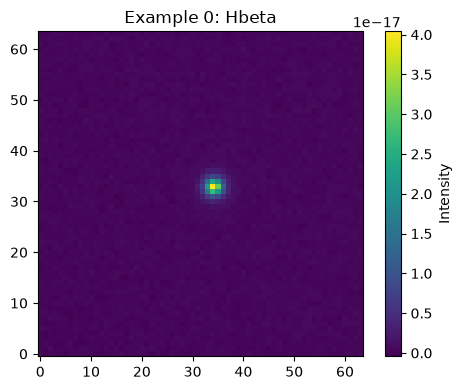

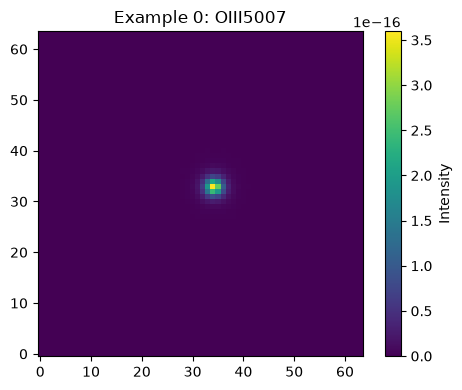

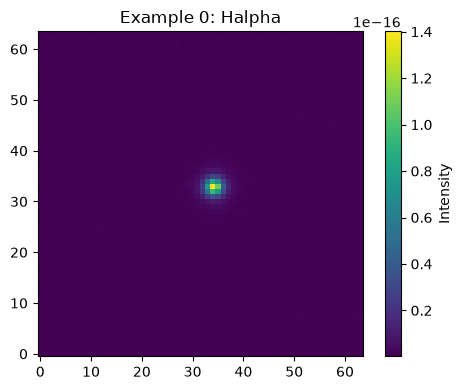

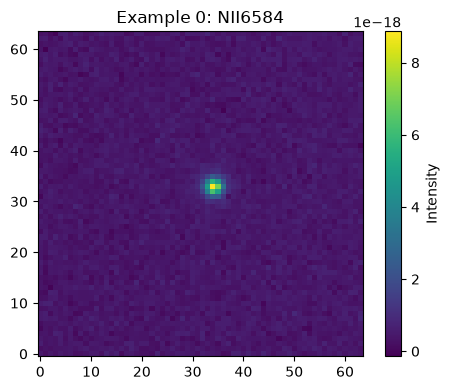

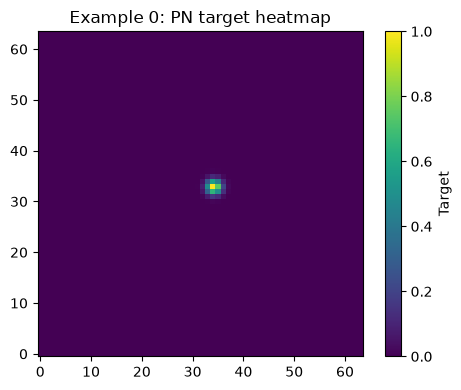

In [7]:
i = 0

for c, name in enumerate(line_names):
    plt.figure(figsize=(5, 4))
    plt.imshow(X[i, :, :, c], origin="lower")
    plt.colorbar(label="Intensity")
    plt.title(f"Example {i}: {name}")
    plt.tight_layout()
    plt.show()

plt.figure(figsize=(5, 4))
plt.imshow(Y[i, :, :, 0], origin="lower")
plt.colorbar(label="Target")
plt.title(f"Example {i}: PN target heatmap")
plt.tight_layout()
plt.show()


## 8. Leakage-safe train / validation / test split

The split is performed on **groups**, never on individual patches.

`group_ids` should be defined upstream so that two samples that overlap or share the same parent content cannot have different group IDs. If you have only one large parent map, create spatial split regions with a guard band at least as wide as the dependence/overlap scale and assign patches by region.

The helper below tries several group-level splits and chooses one with a reasonable positive-sample balance. It then verifies that the three group sets are disjoint.


In [8]:
# Image-level positive flag, used only to keep class balance reasonable.
has_pn = np.any(Y >= 0.999, axis=(1, 2, 3)).astype(np.int32)

def best_group_holdout(indices, groups, labels, holdout_fraction, seed, n_trials=200):
    """Choose a leakage-safe group holdout with roughly preserved positive rate."""
    indices = np.asarray(indices)
    groups = np.asarray(groups)
    labels = np.asarray(labels)

    if len(np.unique(groups[indices])) < 2:
        raise ValueError(
            "Not enough independent groups to make a leakage-safe split. "
            "Define finer non-overlapping spatial groups with guard bands, or use more parent fields."
        )

    overall_pos = labels[indices].mean()
    target_n = holdout_fraction * len(indices)
    best = None

    for t in range(n_trials):
        splitter = GroupShuffleSplit(
            n_splits=1,
            test_size=holdout_fraction,
            random_state=seed + t
        )

        keep_local, hold_local = next(
            splitter.split(
                np.zeros(len(indices)),
                labels[indices],
                groups=groups[indices]
            )
        )

        keep_idx = indices[keep_local]
        hold_idx = indices[hold_local]

        hold_frac_error = abs(len(hold_idx) - target_n) / max(len(indices), 1)
        balance_error = (
            abs(labels[keep_idx].mean() - overall_pos)
            + abs(labels[hold_idx].mean() - overall_pos)
        )
        score = hold_frac_error + balance_error

        if best is None or score < best[0]:
            best = (score, keep_idx, hold_idx)

    return best[1], best[2]


all_idx = np.arange(len(X))

train_idx, temp_idx = best_group_holdout(
    all_idx,
    group_ids,
    has_pn,
    holdout_fraction=0.20,
    seed=SEED
)

val_idx, test_idx = best_group_holdout(
    temp_idx,
    group_ids,
    has_pn,
    holdout_fraction=0.50,
    seed=SEED + 1000
)

# Hard safety checks: no split may share a group.
train_groups = set(group_ids[train_idx])
val_groups = set(group_ids[val_idx])
test_groups = set(group_ids[test_idx])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

# ---- Normalize with TRAINING DATA ONLY ----
# First move the very small astronomical fluxes into a numerically convenient
# range. FLUX_SCALE must also be applied to the real DAP maps at inference.
X_scaled = X.astype(np.float64) * FLUX_SCALE

# Compute normalization statistics from the TRAINING SPLIT ONLY.
channel_means = np.mean(
    X_scaled[train_idx],
    axis=(0, 1, 2),
    dtype=np.float64
)

channel_stds = np.std(
    X_scaled[train_idx],
    axis=(0, 1, 2),
    dtype=np.float64
)

# Do not use an absolute floor such as 1e-12 here: after flux rescaling these
# standard deviations should be ordinary positive numbers. If not, stop and
# inspect the corresponding input channel.
if np.any(~np.isfinite(channel_means)):
    raise ValueError(f"Invalid channel means: {channel_means}")

if np.any(~np.isfinite(channel_stds)) or np.any(channel_stds <= 0):
    raise ValueError(f"Invalid channel standard deviations: {channel_stds}")

X_train = (
    (X_scaled[train_idx] - channel_means[None, None, None, :])
    / channel_stds[None, None, None, :]
).astype(np.float32)

X_val = (
    (X_scaled[val_idx] - channel_means[None, None, None, :])
    / channel_stds[None, None, None, :]
).astype(np.float32)

X_test = (
    (X_scaled[test_idx] - channel_means[None, None, None, :])
    / channel_stds[None, None, None, :]
).astype(np.float32)

# Sanity check: the training split should now be approximately mean 0/std 1.
normalized_train_means = X_train.mean(axis=(0, 1, 2))
normalized_train_stds = X_train.std(axis=(0, 1, 2))

print("FLUX_SCALE:", FLUX_SCALE)
print("Train-only channel means (after scaling):", channel_means)
print("Train-only channel stds  (after scaling):", channel_stds)
print("Normalized train means:", normalized_train_means)
print("Normalized train stds :", normalized_train_stds)


Y_train, Y_val, Y_test = Y[train_idx], Y[val_idx], Y[test_idx]

types_train = sample_types[train_idx]
types_val = sample_types[val_idx]
types_test = sample_types[test_idx]

def split_report(name, idx, types):
    neg_mask = ~has_pn[idx].astype(bool)
    compact_neg = np.isin(
        types,
        ["compact_nonpn", "compact_non-pn", "nonpn_compact", "hard_negative"]
    )
    background = np.isin(types, ["background", "empty", "blank"])

    print(
        f"{name:5s}: N={len(idx):5d} | groups={len(np.unique(group_ids[idx])):4d} "
        f"| PN-containing={has_pn[idx].mean():.3f} "
        f"| compact non-PN={compact_neg.sum():4d} "
        f"| background={background.sum():4d}"
    )

print("Leakage-safe split:")
split_report("Train", train_idx, types_train)
split_report("Val", val_idx, types_val)
split_report("Test", test_idx, types_test)

# Audit the critical negative-sampling issue.
negative_train = ~has_pn[train_idx].astype(bool)
compact_negative_train = negative_train & np.isin(
    types_train,
    ["compact_nonpn", "compact_non-pn", "nonpn_compact", "hard_negative"]
)

if negative_train.sum() == 0:
    raise ValueError("Training set contains no negative samples.")

compact_fraction = compact_negative_train.sum() / negative_train.sum()
print(f"Fraction of training negatives that are compact non-PNe: {compact_fraction:.3f}")

if compact_fraction < 0.5:
    print(
        "WARNING: most training negatives are not labelled compact non-PNe. "
        "Regenerate the dataset so realistic compact non-PN sources dominate the negative pool."
    )



FLUX_SCALE: 1e+18
Train-only channel means (after scaling): [ 6.55170556  1.28012028 30.54480726  8.59103849]
Train-only channel stds  (after scaling): [ 500.50843468    5.39762349 2723.75963779  543.9265711 ]
Normalized train means: [-9.7359718e-11 -2.2499877e-10 -5.3268345e-10 -5.8508998e-10]
Normalized train stds : [0.999974   0.99999964 0.999977   0.9999775 ]
Leakage-safe split:
Train: N= 7997 | groups= 111 | PN-containing=0.745 | compact non-PN=1905 | background= 133
Val  : N= 1000 | groups=  14 | PN-containing=0.743 | compact non-PN= 241 | background=  16
Test : N= 1003 | groups=  14 | PN-containing=0.747 | compact non-PN= 235 | background=  19
Fraction of training negatives that are compact non-PNe: 0.935


### Required upstream change for realistic negatives

The U-Net cannot turn an empty/background patch into a realistic non-PN negative by itself; this must be fixed when `allcompactsources_10000_norm.npz` is created.

For every negative sample, preferentially center the crop on a **realistic compact non-PN source** (for example a compact H II region, SNR, DIG knot, or another relevant contaminant in your science case). The crucial controls are:

1. Render/extract positives and compact negatives with the **same PSF/morphology machinery**.
2. Match or overlap their distributions in apparent size, peak flux/total flux, S/N, and local background.
3. Let the discriminating information be the emission-line pattern/ratios, not merely the presence of a point-like source.
4. Keep a smaller fraction of pure-background negatives for robustness.
5. If hard-negative mining is used later, mine false positives **only from training groups**.

A practical starting composition is to make the majority of negative samples compact non-PNe and a minority pure background. Tune the exact mix using validation performance on the real contaminant population, not test performance.

When saving the dataset, add at least:

```python
np.savez(
    ...,
    X=X,
    Y=Y,
    group_ids=np.asarray(group_ids),        # leakage-safe parent/region ID
    sample_types=np.asarray(sample_types),  # 'pn', 'compact_nonpn', 'background'
)
```

If multiple crops come from the same compact object, nearby overlapping area, or parent image content, give them the same `group_id` (or a coarser region ID) so they cannot cross splits.


## 9. Data augmentation

Only spatial transformations are used here. The same transformation is applied to the four input channels and the target heatmap.

Augmentation happens **after** splitting, so augmented versions of a training patch can never appear in validation/test.


In [9]:
def augment(x, y):
    # Random 0, 90, 180 or 270 degree rotation
    k = tf.random.uniform(
        shape=[],
        minval=0,
        maxval=4,
        dtype=tf.int32
    )

    x = tf.image.rot90(x, k)
    y = tf.image.rot90(y, k)

    # Horizontal flip
    do_lr = tf.random.uniform([]) > 0.5
    x = tf.cond(do_lr, lambda: tf.image.flip_left_right(x), lambda: x)
    y = tf.cond(do_lr, lambda: tf.image.flip_left_right(y), lambda: y)

    # Vertical flip
    do_ud = tf.random.uniform([]) > 0.5
    x = tf.cond(do_ud, lambda: tf.image.flip_up_down(x), lambda: x)
    y = tf.cond(do_ud, lambda: tf.image.flip_up_down(y), lambda: y)

    return x, y


## 10. Build TensorFlow datasets

In [10]:
train_ds = (
    tf.data.Dataset
    .from_tensor_slices((X_train, Y_train))
    .shuffle(len(X_train), seed=SEED)
    .map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    tf.data.Dataset
    .from_tensor_slices((X_val, Y_val))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    tf.data.Dataset
    .from_tensor_slices((X_test, Y_test))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


I0000 00:00:1788386167.433953   32645 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5518 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


## 11. Small U-Net

In [11]:
def conv_block(x, filters):
    x = layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal"
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal"
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    return x


def build_unet(input_shape=(64, 64, 4)):
    inputs = keras.Input(shape=input_shape)

    # Encoder
    c1 = conv_block(inputs, 32)
    p1 = layers.MaxPooling2D((2, 2))(c1)

    c2 = conv_block(p1, 64)
    p2 = layers.MaxPooling2D((2, 2))(c2)

    c3 = conv_block(p2, 128)
    p3 = layers.MaxPooling2D((2, 2))(c3)

    # Bottleneck
    b = conv_block(p3, 256)
    b = layers.Dropout(0.20)(b)

    # Decoder
    u3 = layers.Conv2DTranspose(
        128, kernel_size=2, strides=2, padding="same"
    )(b)
    u3 = layers.Concatenate()([u3, c3])
    c4 = conv_block(u3, 128)

    u2 = layers.Conv2DTranspose(
        64, kernel_size=2, strides=2, padding="same"
    )(c4)
    u2 = layers.Concatenate()([u2, c2])
    c5 = conv_block(u2, 64)

    u1 = layers.Conv2DTranspose(
        32, kernel_size=2, strides=2, padding="same"
    )(c5)
    u1 = layers.Concatenate()([u1, c1])
    c6 = conv_block(u1, 32)

    outputs = layers.Conv2D(
        1,
        kernel_size=1,
        activation="sigmoid",
        name="pn_heatmap"
    )(c6)

    return keras.Model(inputs, outputs, name="PN_UNet")


model = build_unet()
model.summary()
with open("model_summary.txt", "w") as f:
    model.summary(print_fn=lambda line: f.write(line + "\n"))

Model: "PN_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64, 64, 4) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │      1,152 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64, 64,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │      9,216 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 32, 32,    │          0 │ re_lu_1[0][0]     │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │     18,432 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 32, 32,    │     36,864 │ re_lu_2[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 16, 16,    │          0 │ re_lu_3[0][0]     │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 16, 16,    │     73,728 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        512 │ conv2d_4[0][0]  

 Total params: 1,930,113 (7.36 MB)

 Trainable params: 1,927,297 (7.35 MB)

 Non-trainable params: 2,816 (11.00 KB)

## 12. Center heatmap focal loss

This is useful because almost all pixels are background.

It assumes the center of a true PN reaches a target value very close to `1.0`, while nearby pixels can contain a Gaussian-like soft target.


In [12]:
@tf.keras.utils.register_keras_serializable()
def center_focal_loss(y_true, y_pred):
    eps = 1e-6

    y_pred = tf.clip_by_value(
        y_pred,
        eps,
        1.0 - eps
    )

    # PN center pixels
    positive = tf.cast(y_true >= 0.999, tf.float32)

    # All other pixels
    negative = tf.cast(y_true < 0.999, tf.float32)

    # Nearby Gaussian pixels are penalized less than distant background
    negative_weights = tf.pow(1.0 - y_true, 4.0)

    positive_loss = (
        -tf.math.log(y_pred)
        * tf.pow(1.0 - y_pred, 2.0)
        * positive
    )

    negative_loss = (
        -tf.math.log(1.0 - y_pred)
        * tf.pow(y_pred, 2.0)
        * negative_weights
        * negative
    )

    num_positive = tf.reduce_sum(positive)

    total_loss = (
        tf.reduce_sum(positive_loss)
        + tf.reduce_sum(negative_loss)
    )

    return tf.cond(
        num_positive > 0,
        lambda: total_loss / num_positive,
        lambda: total_loss
    )


## 13. Compile the model

In [13]:
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss=center_focal_loss
)

'''
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss=keras.losses.BinaryCrossentropy()
)
'''

'\nmodel.compile(\n    optimizer=keras.optimizers.Adam(\n        learning_rate=LEARNING_RATE\n    ),\n    loss=keras.losses.BinaryCrossentropy()\n)\n'

## 14. Training callbacks

In [14]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_PN_UNet_focal_all_grouped.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
        verbose=1
    )
]


## 15. Train

In [15]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=MAX_EPOCHS,
    callbacks=callbacks
)


Epoch 1/100


/home/sina/miniconda3/envs/master_thesis/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1788386173.793226   32733 service.cc:153] XLA service 0x757fd005ea60 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1788386173.793414   32733 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4070 Laptop GPU, Compute Capability 8.9 (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.9.0; DNN: 9.23.1)
I0000 00:00:1788386173.883133   32733 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1788386174.384904   32733 cuda_dnn.cc:461] Loaded cuDNN version 92301
I0000 00:00:1788386187.567096   32733 devi

250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - loss: 53.1249
Epoch 1: val_loss improved from None to 14.24561, saving model to best_PN_UNet_focal_all_grouped.keras

Epoch 1: finished saving model to best_PN_UNet_focal_all_grouped.keras
250/250 ━━━━━━━━━━━━━━━━━━━━ 39s 88ms/step - loss: 53.1249 - val_loss: 14.2456 - learning_rate: 3.0000e-04
Epoch 2/100
249/250 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 6.8752
Epoch 2: val_loss improved from 14.24561 to 4.94576, saving model to best_PN_UNet_focal_all_grouped.keras

Epoch 2: finished saving model to best_PN_UNet_focal_all_grouped.keras
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 6.8696 - val_loss: 4.9458 - learning_rate: 3.0000e-04
Epoch 3/100
248/250 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 4.0722
Epoch 3: val_loss improved from 4.94576 to 3.22635, saving model to best_PN_UNet_focal_all_grouped.keras

Epoch 3: finished saving model to best_PN_UNet_focal_all_grouped.keras
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 4.0676 - val_

## 16. Plot the training history

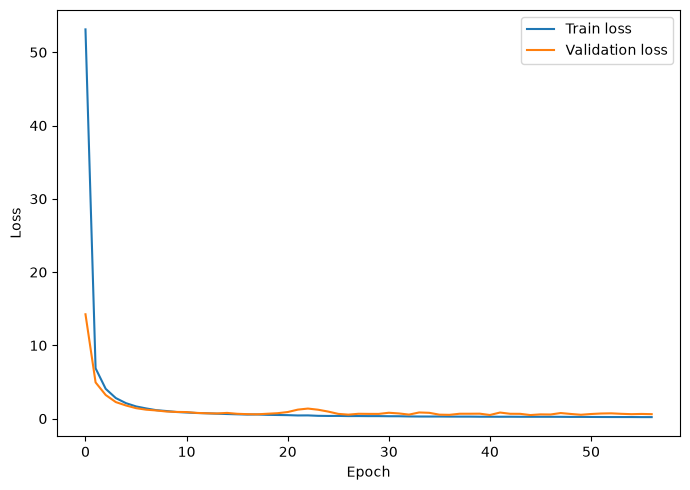

In [16]:
plt.figure(figsize=(7, 5))
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()


## 17. Evaluate test loss

In [17]:
test_loss = model.evaluate(test_ds, verbose=1)
print("Test loss:", test_loss)


32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - loss: 0.5019
Test loss: 0.5019168853759766


## 18. Predict one example

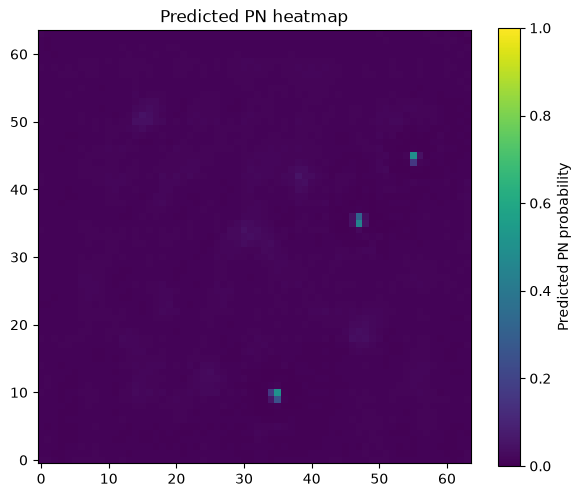

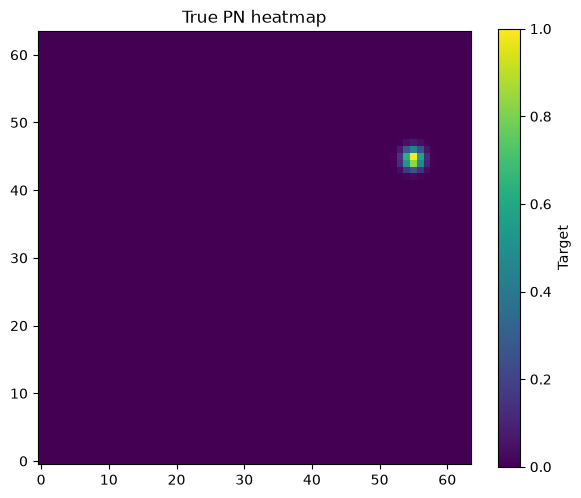

In [18]:
i = 50

pred = model.predict(
    X_test[i:i+1],
    verbose=0
)[0, :, :, 0]

truth = Y_test[i, :, :, 0]

plt.figure(figsize=(6, 5))
plt.imshow(pred, origin="lower", vmin=0, vmax=1)
plt.colorbar(label="Predicted PN probability")
plt.title("Predicted PN heatmap")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
plt.imshow(truth, origin="lower", vmin=0, vmax=1)
plt.colorbar(label="Target")
plt.title("True PN heatmap")
plt.tight_layout()
plt.show()


## 19. Find PN centers from a predicted heatmap

In [19]:
def find_pn_centers(
    heatmap,
    threshold=0.30,
    min_distance=3
):
    size = 2 * min_distance + 1

    local_max = (
        heatmap
        == maximum_filter(
            heatmap,
            size=size,
            mode="constant"
        )
    )

    detected = local_max & (heatmap >= threshold)

    y, x = np.where(detected)
    scores = heatmap[y, x]

    order = np.argsort(scores)[::-1]

    return np.column_stack(
        [x[order], y[order], scores[order]]
    )


detections = find_pn_centers(
    pred,
    threshold=PEAK_THRESHOLD,
    min_distance=MIN_DISTANCE
)

print("Detected PN centers [x, y, score]:")
print(detections)


Detected PN centers [x, y, score]:
[[35.         10.          0.50733072]
 [55.         45.          0.49435744]
 [47.         35.          0.44887891]]


## 20. Plot detections over the predicted heatmap

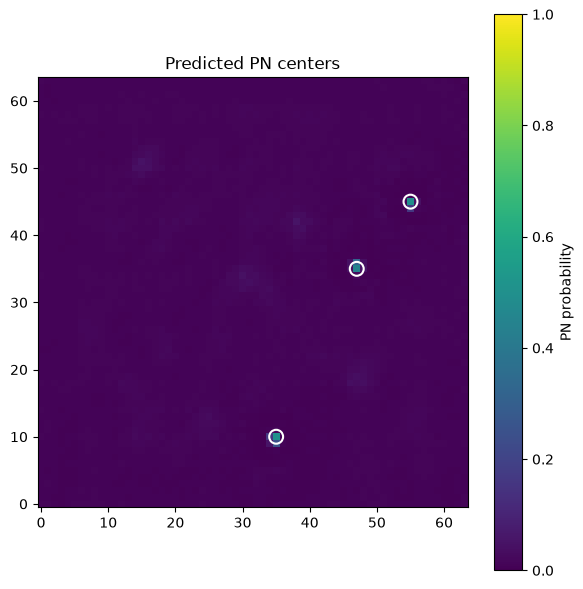

In [20]:
plt.figure(figsize=(6, 6))
plt.imshow(pred, origin="lower", vmin=0, vmax=1)
plt.colorbar(label="PN probability")

if len(detections) > 0:
    plt.scatter(
        detections[:, 0],
        detections[:, 1],
        facecolors="none",
        edgecolors="white",
        s=100,
        linewidths=1.5
    )

plt.title("Predicted PN centers")
plt.tight_layout()
plt.show()


## 21. Extract true PN centers from the target heatmap

For the evaluation below, a PN center is taken to be a local maximum with target value close to 1.


In [21]:
def find_true_centers(
    target,
    threshold=0.999,
    min_distance=1
):
    size = 2 * min_distance + 1

    local_max = (
        target
        == maximum_filter(
            target,
            size=size,
            mode="constant"
        )
    )

    detected = local_max & (target >= threshold)

    y, x = np.where(detected)

    return np.column_stack([x, y]).astype(np.float32)


## 22. Match predicted detections to true PNe

A predicted PN is considered correct if it lies within `MATCH_TOLERANCE` pixels of an unmatched true PN.


In [22]:
def match_detections(
    predicted,
    true_centers,
    tolerance=3.0
):
    if len(predicted) == 0:
        return 0, 0, len(true_centers), []

    if len(true_centers) == 0:
        return 0, len(predicted), 0, []

    pred_xy = np.asarray(predicted[:, :2], dtype=np.float32)
    true_xy = np.asarray(true_centers, dtype=np.float32)

    used_true = set()

    tp = 0
    localization_errors = []

    # Predictions are already sorted by confidence
    for px, py in pred_xy:

        distances = np.sqrt(
            (true_xy[:, 0] - px)**2
            + (true_xy[:, 1] - py)**2
        )

        order = np.argsort(distances)

        for j in order:

            if distances[j] > tolerance:
                break

            if j not in used_true:
                used_true.add(j)

                tp += 1

                # Save localization error for this TP
                localization_errors.append(
                    distances[j]
                )

                break

    fp = len(pred_xy) - tp
    fn = len(true_xy) - tp

    return tp, fp, fn, localization_errors

## 23. Source-level precision and recall on the full test set

In [23]:
def evaluate_detector(
    model,
    X_test,
    Y_test,
    threshold=0.30,
    min_distance=2,
    match_tolerance=3.0
):

    predictions = model.predict(
        X_test,
        verbose=1
    )

    total_tp = 0
    total_fp = 0
    total_fn = 0

    # NEW: image-level negatives
    total_tn = 0
    total_negative_images = 0
    total_negative_images_with_fp = 0

    all_localization_errors = []

    for pred_map, true_map in zip(
        predictions,
        Y_test
    ):

        pred_centers = find_pn_centers(
            pred_map[:, :, 0],
            threshold=threshold,
            min_distance=min_distance
        )

        true_centers = find_true_centers(
            true_map[:, :, 0]
        )

        # NEW
        if len(true_centers) == 0:
            total_negative_images += 1

            if len(pred_centers) == 0:
                total_tn += 1
            else:
                total_negative_images_with_fp += 1

        tp, fp, fn, errors = match_detections(
            pred_centers,
            true_centers,
            tolerance=match_tolerance
        )

        total_tp += tp
        total_fp += fp
        total_fn += fn

        all_localization_errors.extend(errors)

    precision = (
        total_tp / (total_tp + total_fp)
        if total_tp + total_fp > 0
        else 0.0
    )

    recall = (
        total_tp / (total_tp + total_fn)
        if total_tp + total_fn > 0
        else 0.0
    )

    f1 = (
        2 * precision * recall
        / (precision + recall)
        if precision + recall > 0
        else 0.0
    )

    # NEW
    specificity = (
        total_tn / total_negative_images
        if total_negative_images > 0
        else np.nan
    )

    false_positive_image_rate = (
        total_negative_images_with_fp / total_negative_images
        if total_negative_images > 0
        else np.nan
    )

    errors = np.asarray(all_localization_errors)

    if len(errors) > 0:
        mean_error = np.mean(errors)
        median_error = np.median(errors)
        rmse_error = np.sqrt(np.mean(errors**2))
        std_error = np.std(errors)
    else:
        mean_error = np.nan
        median_error = np.nan
        rmse_error = np.nan
        std_error = np.nan

    return {
        "TP": total_tp,
        "FP": total_fp,
        "FN": total_fn,
        "TN": total_tn,
        
        "negative_images": total_negative_images,
        "negative_images_with_FP": total_negative_images_with_fp,
        "specificity": specificity,
        "false_positive_image_rate": false_positive_image_rate,

        "precision": precision,
        "recall": recall,
        "f1": f1,

        "mean_localization_error": mean_error,
        "median_localization_error": median_error,
        "rmse_localization_error": rmse_error,
        "std_localization_error": std_error,

        "localization_errors": errors
    }

## Compact-negative false-positive audit

Overall precision can hide the exact failure mode you are trying to prevent. Evaluate pure background and compact non-PN negatives separately.

A good model should not only avoid hallucinating PNe in empty background; it should also keep a low false-positive rate on compact non-PN sources.


In [24]:
def negative_subset_fp_rate(model, X_subset, Y_subset, type_subset, threshold):
    pred_all = model.predict(X_subset, verbose=0)

    rows = []
    for target_type, aliases in {
        "compact_nonpn": ["compact_nonpn", "compact_non-pn", "nonpn_compact", "hard_negative"],
        "background": ["background", "empty", "blank"],
    }.items():
        mask = np.isin(type_subset, aliases)
        # Restrict to genuinely PN-free images.
        mask &= ~np.any(Y_subset >= 0.999, axis=(1, 2, 3))

        n = int(mask.sum())
        if n == 0:
            rows.append((target_type, 0, np.nan))
            continue

        with_fp = 0
        for pred_map in pred_all[mask]:
            detections = find_pn_centers(
                pred_map[:, :, 0],
                threshold=threshold,
                min_distance=MIN_DISTANCE
            )
            with_fp += int(len(detections) > 0)

        rows.append((target_type, n, with_fp / n))

    print("negative_type     N     image_FP_rate")
    for name, n, rate in rows:
        print(f"{name:15s} {n:5d}   {rate if np.isfinite(rate) else np.nan:.3f}")


## 24. Tune the detection threshold on the validation set

Do **not** choose the final threshold from the test set.

This cell scans a small threshold grid using the validation set and reports source-level precision, recall and F1.


In [25]:
thresholds = np.arange(0.10, 0.91, 0.10)

results = []

for threshold in thresholds:
    m = evaluate_detector(
        model,
        X_val,
        Y_val,
        threshold=float(threshold),
        min_distance=MIN_DISTANCE,
        match_tolerance=MATCH_TOLERANCE
    )

    results.append([
        threshold,
        m["precision"],
        m["recall"],
        m["f1"]
    ])

results = np.asarray(results)

print("threshold   precision   recall   F1")
for row in results:
    print(
        f"{row[0]:.2f}        "
        f"{row[1]:.3f}       "
        f"{row[2]:.3f}    "
        f"{row[3]:.3f}"
    )

best_index = np.argmax(results[:, 3])
best_threshold = results[best_index, 0]

print("\nBest validation threshold:", best_threshold)


32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
threshold   precision   recall   F1
0.10        0.389       0.987    0.558
0.20        0.457       0.975    0.622
0.30        0.514       0.887    0.651
0.40        0.603       0.693    0.645
0.50        0.720       0.437    0.544
0.60        0.846       0.211    0.338
0.70        0.953       0.042    0.080
0.80        1.000       0.001    0.002
0.90        0.000       0.000    0.000

Best validation threshold: 0.30000000000000004


## 25. Plot threshold dependence

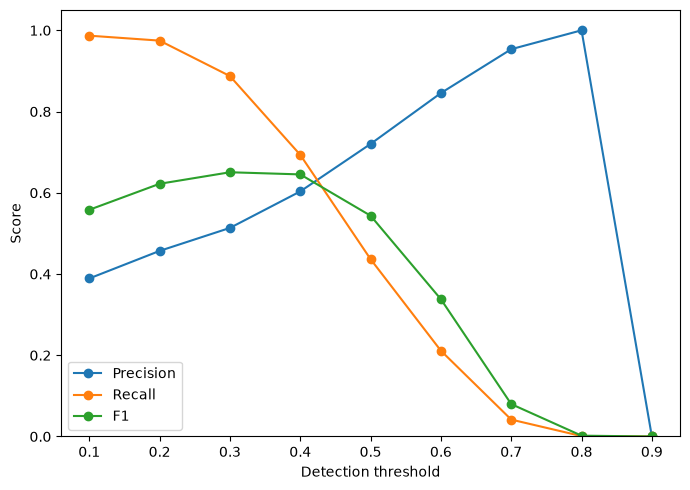

In [26]:
plt.figure(figsize=(7, 5))
plt.plot(results[:, 0], results[:, 1], marker="o", label="Precision")
plt.plot(results[:, 0], results[:, 2], marker="o", label="Recall")
plt.plot(results[:, 0], results[:, 3], marker="o", label="F1")
plt.xlabel("Detection threshold")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()


## 26. Final source-level test metrics using the validation-selected threshold

In [27]:
final_metrics = evaluate_detector(
    model,
    X_test,
    Y_test,
    threshold=float(best_threshold),
    min_distance=MIN_DISTANCE,
    match_tolerance=MATCH_TOLERANCE
)

print("Final test metrics:")
for key, value in final_metrics.items():
    print(f"{key}: {value}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step
Final test metrics:
TP: 885
FP: 777
FN: 125
TN: 119
negative_images: 254
negative_images_with_FP: 135
specificity: 0.468503937007874
false_positive_image_rate: 0.531496062992126
precision: 0.5324909747292419
recall: 0.8762376237623762
f1: 0.6624251497005988
mean_localization_error: 0.1853107362985611
median_localization_error: 0.0
rmse_localization_error: 0.4304773211479187
std_localization_error: 0.38854944705963135
localization_errors: [0. 0. 0. 0. 0. 0. 1. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 1.
 0. 0. 0. 0. 1. 0. 1. 1. 0. 1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 1. 0. 1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 1. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.
 1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 1. 0. 0. 0. 0. 1. 0. 1.
 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.
 0. 1. 

## 27. Save normalization information for inference

Inference must use **exactly the same preprocessing** as training:

```python
image_scaled = image_raw * FLUX_SCALE
image_normalized = (image_scaled - channel_means) / channel_stds
```

Do not hand-copy or recompute these values from the real NGC 253 image.
Load them from `PN_UNet_normalization.npz`.


In [28]:
np.savez(
    "PN_UNet_normalization.npz",
    line_names=np.asarray(line_names),
    flux_scale=np.float64(FLUX_SCALE),
    channel_means=np.asarray(channel_means, dtype=np.float64),
    channel_stds=np.asarray(channel_stds, dtype=np.float64)
)

print("Saved TRAIN-ONLY normalization information.")
print("  FLUX_SCALE   :", FLUX_SCALE)
print("  channel_means:", channel_means)
print("  channel_stds :", channel_stds)


Saved TRAIN-ONLY normalization information.
  FLUX_SCALE   : 1e+18
  channel_means: [ 6.55170556  1.28012028 30.54480726  8.59103849]
  channel_stds : [ 500.50843468    5.39762349 2723.75963779  543.9265711 ]


## Notes

- The four channels remain in the order:
  1. `Hbeta`
  2. `OIII5007`
  3. `Halpha`
  4. `NII6584`

- Pixel-wise accuracy is **not** a useful metric here because almost all pixels are background.

- The scientifically useful metrics are source-level:
  - completeness / recall
  - purity / precision
  - F1
  - localization error
  - completeness versus PN flux/SNR and local background

- The center focal loss assumes that each target PN has at least one pixel with value approximately `1.0`.
  If your `Y` targets use a different convention, modify the positive-pixel definition accordingly.

- **Inference normalization must match training exactly.** Load
  `flux_scale`, `channel_means`, and `channel_stds` from
  `PN_UNet_normalization.npz`; do not recompute them from the DAP image.

- The correct inference preprocessing is:

  ```python
  image_scaled = image_raw * FLUX_SCALE
  image_normalized = (
      image_scaled - channel_means[None, None, :]
  ) / channel_stds[None, None, :]
  ```
